In [1]:
# 단순 전후 비교: 시행 전 3개월과 시행일부터 3개월의 실거래 ㎡당 중위가격을 비교한다.
# 상승률 = (이후 중위가격 / 이전 중위가격 - 1) × 100. 거래 구성과 다른 정책의 영향도 포함된다.
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', message='Pandas requires version')
import numpy as np
import pandas as pd
from IPython.display import display
root = next(p for p in [Path.cwd(), Path.cwd().parent] if (p/'data').is_dir())
policy_dir = next((root/'data').glob('06*'))
out = root/'outputs'/'06_simple_before_after'
out.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 10)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
def save(frame, name):
    frame.to_csv(out/(name+'.csv'), index=False, encoding='utf-8-sig')
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Workbook contains no default style')
    raw = pd.read_excel(root/'data'/'서울_아파트_매매_실거래가_2017-2026_통합.xlsx', dtype=str)
raw.columns = raw.columns.str.strip()
for c in raw:
    raw[c] = raw[c].astype('string').str.strip()
def num(s): return pd.to_numeric(s.str.replace(',', '', regex=False), errors='coerce')
df = raw.copy()
df['가격'] = num(df['거래금액(만원)'])
df['면적'] = num(df['전용면적(㎡)'])
df['날짜'] = pd.to_datetime(df['계약년월']+df['계약일'].str.zfill(2), format='%Y%m%d', errors='coerce')
df['구'] = df['시군구'].str.extract(r'^서울특별시\s+(\S+구)', expand=False)
df['동'] = df['시군구'].str.split().str[-1]
ok = (df['구'].notna() & df['주택유형'].eq('아파트') & df['날짜'].notna() &
      df['가격'].gt(0) & df['면적'].gt(0) & df['해제사유발생일'].fillna('').isin(['', '-', '0']))
df = df[ok.fillna(False)].copy()
df['㎡당가격'] = df['가격']/df['면적']
first, last = df['날짜'].min(), df['날짜'].max()
print(f'실거래 {len(df):,}건 | {first:%Y-%m-%d}~{last:%Y-%m-%d} | 가격 단위: 만원/㎡')

실거래 530,129건 | 2017-10-28~2026-10-26 | 가격 단위: 만원/㎡


In [2]:
# 날짜 기준으로 정확히 나누며, 전후 3개월 전체가 자료에 포함되지 않으면 계산하지 않는다.
def compare(part, date):
    date = pd.Timestamp(date)
    left, right = date-pd.DateOffset(months=3), date+pd.DateOffset(months=3)
    result = {'이전시작': left, '기준일': date, '이후종료_미포함': right,
              '이전건수': 0, '이후건수': 0, '이전가격': np.nan, '이후가격': np.nan, '상승률_pct': np.nan, '상태': '기간 부족'}
    if left < first or right-pd.Timedelta(days=1) > last:
        return result
    before = part.loc[part['날짜'].ge(left) & part['날짜'].lt(date), '㎡당가격']
    after = part.loc[part['날짜'].ge(date) & part['날짜'].lt(right), '㎡당가격']
    result.update(이전건수=len(before), 이후건수=len(after))
    if min(len(before), len(after)) < 30:
        result['상태'] = '전후 각각 30건 미만'
        return result
    result.update(이전가격=before.median(), 이후가격=after.median(),
                  상승률_pct=(after.median()/before.median()-1)*100, 상태='계산 완료')
    return result

# 대책 목록의 기재일을 그대로 사용한다. 발표일과 세부 조치 시행일은 다를 수 있다.
policies = pd.read_excel(policy_dir/'부동산대책 목록.xlsx')
policies['시행일자'] = pd.to_datetime(policies['시행일자'])
policy_results = pd.DataFrame([
    {'대책명': r['대책명'], **compare(df, r['시행일자'])} for _, r in policies.iterrows()
])
save(policy_results, 'policy_before_after')
# 같은 기준의 구별 결과도 저장한다.
district_results = pd.DataFrame([
    {'대책명': r['대책명'], '자치구': gu, **compare(part, r['시행일자'])}
    for _, r in policies.iterrows() for gu, part in df.groupby('구')
])
save(district_results, 'policy_by_district')
display(policy_results[['대책명', '기준일', '이전가격', '이후가격', '상승률_pct', '상태']])

,대책명,기준일,이전가격,이후가격,상승률_pct,상태
0,6·19 대책,2017-06-19,NaN,NaN,NaN,기간 부족
1,8·2 대책,2017-08-02,NaN,NaN,NaN,기간 부족
2,10·24 가계부채 대책,2017-10-24,NaN,NaN,NaN,기간 부족
3,9·13 대책,2018-09-13,732.08,714.78,-2.36,계산 완료
4,9·21 공급대책,2018-09-21,735.47,714.78,-2.81,계산 완료
5,12·16 대책,2019-12-16,930.79,816.72,-12.26,계산 완료
6,6·17 대책,2020-06-17,907.43,"1,019.11",12.31,계산 완료
7,7·10 대책,2020-07-10,959.39,"1,059.58",10.44,계산 완료
8,8·4 공급대책,2020-08-04,984.09,"1,071.09",8.84,계산 완료
9,2·4 대책,2021-02-04,"1,175.62","1,156.17",-1.65,계산 완료


In [3]:
# 토허제는 지정일이 명확한 아파트 관련 기록을 비교한다. 연장도 원본 기록대로 구분한다.
# 정확한 지정동을 확인할 수 없는 일부 구역은 해당 구 전체의 참고 변화만 계산한다.
tor = pd.read_excel(policy_dir/'서울_토허제_지정해제_이력.xlsx')
tor_rows, tor_excluded, selections = [], [], {}
for i, r in tor.iterrows():
    scope, note, gu = str(r['지정지역(세부)']), str(r['비고']), str(r['지정구'])
    date = pd.to_datetime(r['지정일자'], errors='coerce')
    reason = ''
    if any(w in scope for w in ['도로', '자연녹지', '그린벨트', '개발제한', '집단취락']):
        reason = '아파트 직접 지정 대상 아님/불명확'
    elif gu not in set(df['구']):
        reason = '지정구 미확인'
    elif pd.isna(date) or '역산' in note or '의결일' in note:
        reason = '효력일 미확인/추정'
    elif not any(w in scope for w in ['아파트', '택지개발지구', '전략정비구역', '정비창']):
        reason = '아파트 적용 범위 미확인'
    if reason:
        tor_excluded.append({'원본행': i+2, '구': gu, '범위': scope, '사유': reason})
        continue
    part = df[df['구'].eq(gu)]
    coverage = '구 전체 참고(지정구역과 다름)'
    if '구 전역' in scope:
        coverage = '구 전역'
    elif '국제교류복합지구' in scope:
        dongs = ['삼성동', '대치동', '청담동'] if gu == '강남구' else ['잠실동']
        part = part[part['동'].isin(dongs)]
        coverage = '지정동 아파트'
    kind = '연장·재지정' if ('(연장)' in scope or note.startswith('연장') or '재지정' in note or '재지정' in str(r['사유'])) else '지정·확대'
    result = {'원본행': i+2, '구': gu, '지정범위': scope, '분석범위': coverage, '구분': kind, **compare(part, date)}
    tor_rows.append(result)
    selections[i+2] = part.index
tor_results = pd.DataFrame(tor_rows)
save(tor_results, 'land_permit_by_district')
save(pd.DataFrame(tor_excluded), 'land_permit_excluded')

# 동일 지정일·분석범위의 거래를 합치되, 같은 거래를 중복 집계하지 않는다.
tor_summary = []
for (date, coverage, kind), group in tor_results.groupby(['기준일', '분석범위', '구분'], sort=True):
    ids = np.unique(np.concatenate([selections[i].to_numpy() for i in group['원본행']]))
    gu_names = sorted(group['구'].unique())
    tor_summary.append({'지정일': date, '대상': ', '.join(gu_names) if len(gu_names) <= 4 else f'{len(gu_names)}개 구',
                        '분석범위': coverage, '구분': kind, **compare(df.loc[ids], date)})
tor_summary = pd.DataFrame(tor_summary)
save(tor_summary, 'land_permit_before_after')
display(tor_summary[['지정일', '대상', '분석범위', '구분', '이전가격', '이후가격', '상승률_pct']])
print('세부 결과·계산 제외 사유: outputs/06_simple_before_after')

세부 결과·계산 제외 사유: outputs/06_simple_before_after


,지정일,대상,분석범위,구분,이전가격,이후가격,상승률_pct
0,2020-05-20,용산구,구 전체 참고(지정구역과 다름),지정·확대,"1,478.34","1,513.15",2.36
1,2020-06-23,"강남구, 송파구",지정동 아파트,지정·확대,"2,285.77","2,246.02",-1.74
2,2021-04-27,"강남구, 성동구, 양천구, 영등포구",구 전체 참고(지정구역과 다름),지정·확대,"1,634.65","1,548.04",-5.30
3,2022-05-20,용산구,구 전체 참고(지정구역과 다름),연장·재지정,"1,995.96","1,884.42",-5.59
4,2024-05-20,용산구,구 전체 참고(지정구역과 다름),연장·재지정,"2,070.49","2,176.76",5.13
5,2025-03-24,"강남구, 서초구, 송파구, 용산구",구 전역,지정·확대,"2,587.24","2,486.23",-3.90
6,2025-04-27,"강남구, 성동구, 양천구, 영등포구",구 전체 참고(지정구역과 다름),연장·재지정,"2,012.79","1,881.63",-6.52
7,2025-10-01,"강남구, 서초구, 송파구, 용산구",구 전역,연장·재지정,"2,218.56","2,251.13",1.47
8,2025-10-20,25개 구,구 전역,지정·확대,"1,378.45","1,334.52",-3.19
9,2026-04-27,"강남구, 성동구, 양천구, 영등포구",구 전체 참고(지정구역과 다름),연장·재지정,"1,869.82","2,119.53",13.35


,대책명,기준일,상승률_pct
0,6·17 대책,2020-06-17,12.31
1,12·16 대책,2019-12-16,-12.26
2,4·17 가계부채 관리방안,2026-04-17,11.38


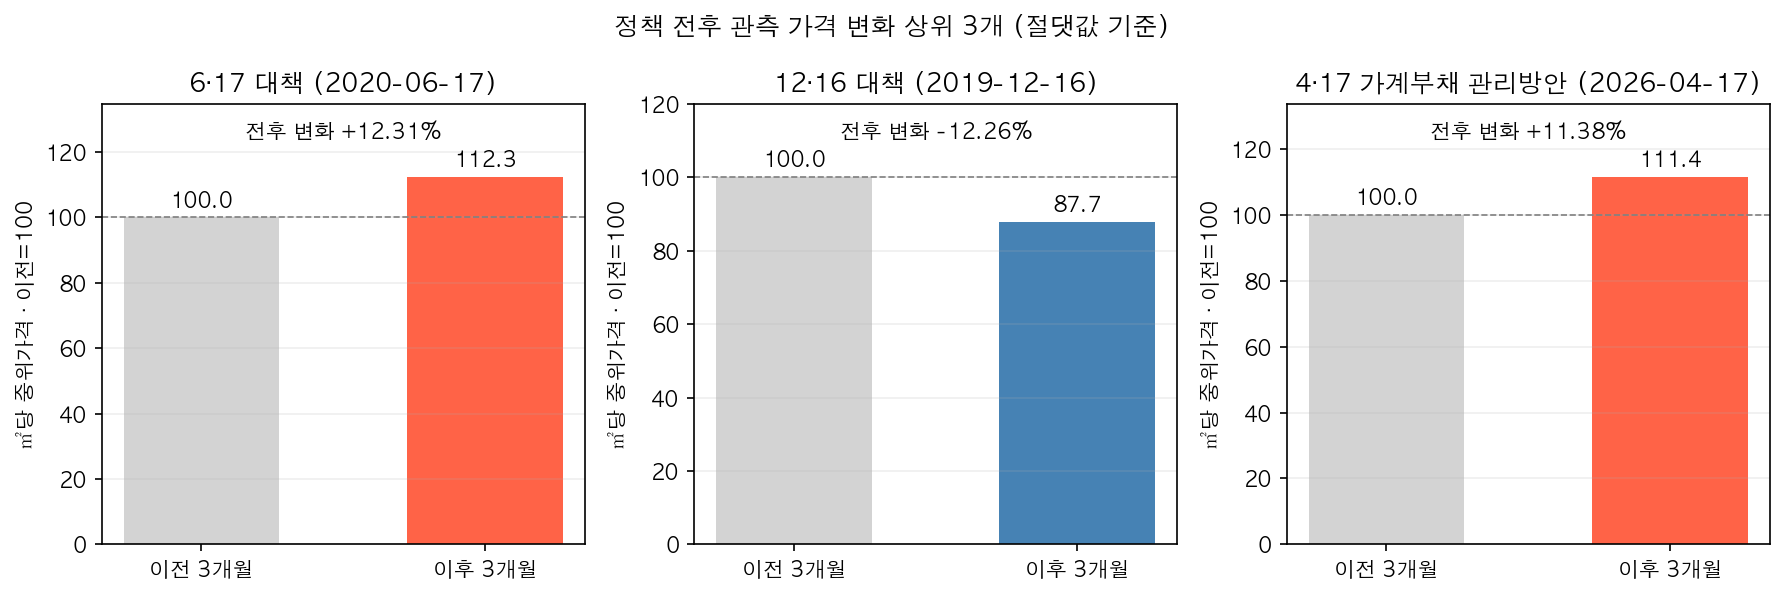

In [4]:
# 동일한 서울 전체 기준으로 비교한 대책 목록에서 |상승률| 상위 3개를 선정한다.
# 관측 변화가 큰 순서이며 정책의 인과적 영향력 순위는 아니다. 토허제는 범위가 달라 이 순위에 섞지 않는다.
top3 = policy_results.dropna(subset=['상승률_pct']).assign(변화크기=lambda x: x['상승률_pct'].abs()).nlargest(3, '변화크기')
save(top3.drop(columns='변화크기'), 'top3_policies')
display(top3[['대책명', '기준일', '상승률_pct']].reset_index(drop=True))

import matplotlib.pyplot as plt
from matplotlib import font_manager
for font in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if font in {f.name for f in font_manager.fontManager.ttflist}:
        plt.rcParams['font.family'] = font
        break
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (_, r) in zip(axes, top3.iterrows()):
    values = [100, r['이후가격']/r['이전가격']*100]
    bars = ax.bar(['이전 3개월', '이후 3개월'], values, color=['lightgray', 'tomato' if r['상승률_pct'] >= 0 else 'steelblue'], width=.55)
    ax.axhline(100, color='gray', linestyle='--', linewidth=.8)
    ax.set(title=f"{r['대책명']} ({r['기준일']:%Y-%m-%d})", ylabel='㎡당 중위가격 · 이전=100', ylim=(0, max(115, max(values)*1.2)))
    ax.bar_label(bars, labels=[f'{v:.1f}' for v in values], padding=3)
    ax.text(.5, .92, f"전후 변화 {r['상승률_pct']:+.2f}%", transform=ax.transAxes, ha='center')
    ax.grid(axis='y', alpha=.2)
fig.suptitle('정책 전후 관측 가격 변화 상위 3개 (절댓값 기준)', fontsize=12)
fig.tight_layout()
fig.savefig(out/'top3_policies.png', dpi=150, bbox_inches='tight')
plt.show()

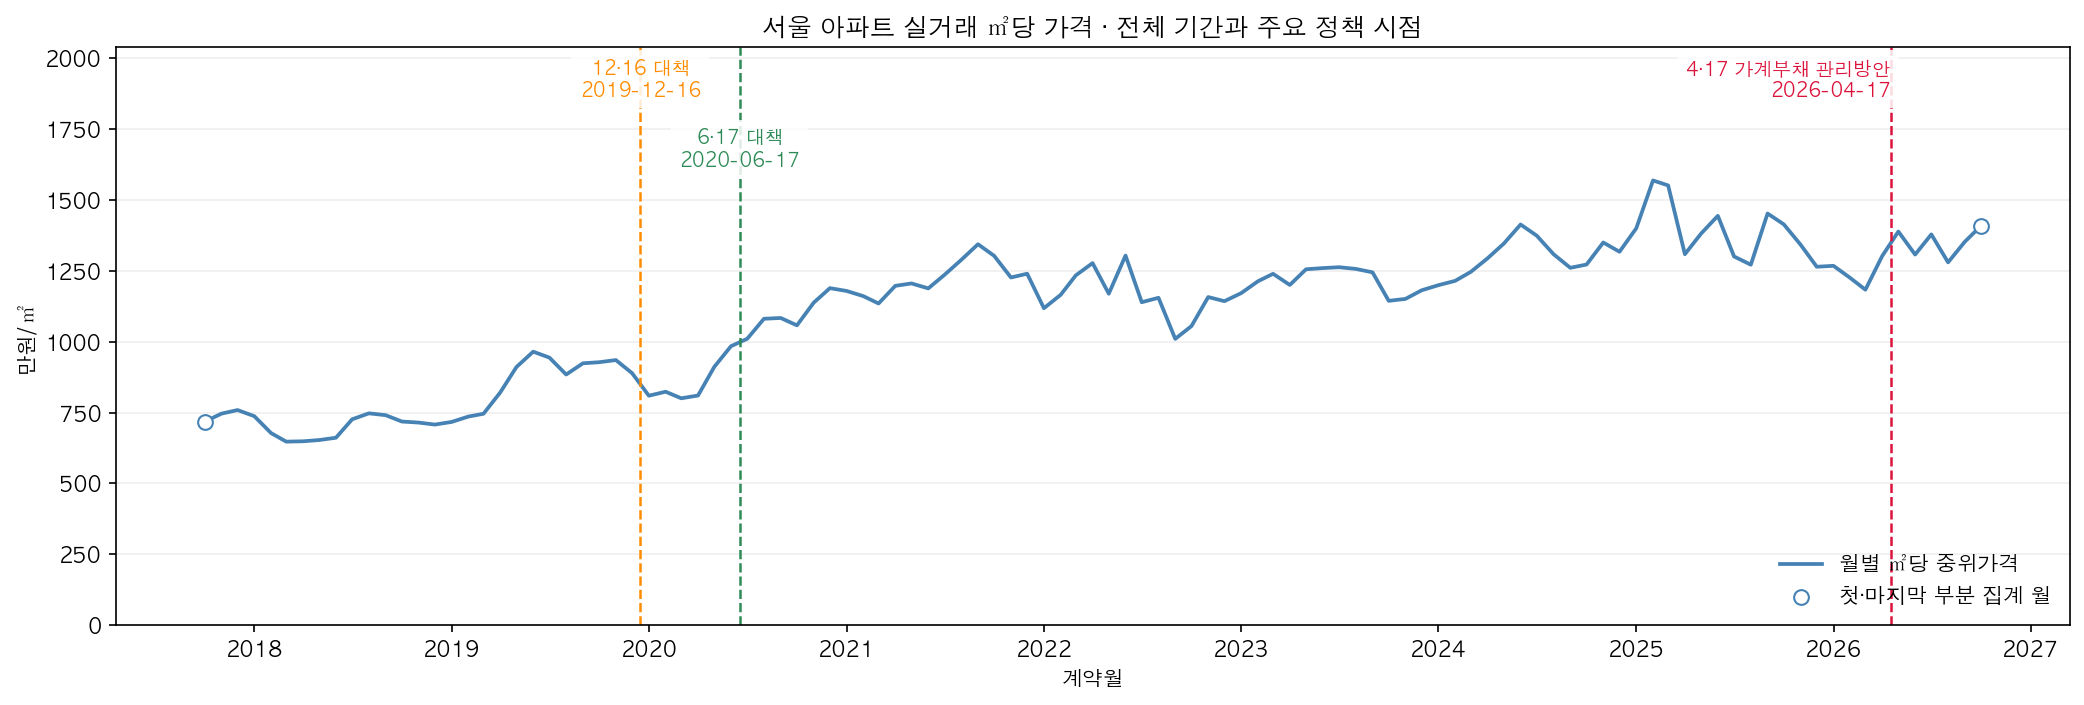

In [5]:
# 전체 거래를 월별로 묶은 ㎡당 중위가격이다. 첫 달·마지막 달은 부분 집계로 별도 표시한다.
monthly = df.groupby(df['날짜'].dt.to_period('M')).agg(
    가격=('㎡당가격', 'median'), 거래수=('㎡당가격', 'size')
)
monthly.index = monthly.index.to_timestamp()
monthly = monthly.asfreq('MS')  # 거래가 없는 달을 임의로 연결하거나 보간하지 않는다.
save(monthly.rename_axis('월').reset_index(), 'monthly_price')
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(monthly.index, monthly['가격'], color='steelblue', linewidth=1.8, label='월별 ㎡당 중위가격')
ax.scatter(monthly.index[[0, -1]], monthly['가격'].iloc[[0, -1]],
           facecolors='white', edgecolors='steelblue', s=50, zorder=4, label='첫·마지막 부분 집계 월')
colors = ['darkorange', 'seagreen', 'crimson']
for color, (_, r) in zip(colors, top3.sort_values('기준일').iterrows()):
    date = pd.Timestamp(r['기준일'])
    ax.axvline(date, color=color, linestyle='--', linewidth=1.2)
    ax.text(date, .86 if date.year == 2020 else .98, f"{r['대책명']}\n{date:%Y-%m-%d}",
            transform=ax.get_xaxis_transform(), ha='center' if date.year < 2026 else 'right',
            va='top', color=color, fontsize=9,
            bbox=dict(facecolor='white', edgecolor='none', alpha=.85))
ax.set(title='서울 아파트 실거래 ㎡당 가격 · 전체 기간과 주요 정책 시점',
       xlabel='계약월', ylabel='만원/㎡')
ax.set_ylim(0, monthly['가격'].max()*1.3)
ax.grid(axis='y', alpha=.2)
ax.legend(loc='lower right', frameon=False)
fig.tight_layout()
fig.savefig(out/'full_price_policy_dates.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# 보유 금리 파일의 CD수익률을 사용한다. 동일 일자 중복은 평균 후 월평균을 계산한다.
rate_source = next(policy_dir.glob('*시장금리*.csv'))
rate_raw = pd.read_csv(rate_source, encoding='cp949')
rate_raw['날짜'] = pd.to_datetime(rate_raw['기준일자'])
rate_raw['금리'] = pd.to_numeric(rate_raw['고시금리'], errors='coerce')
daily_rate = rate_raw[rate_raw['시장금리종류'].eq('CD수익률')].groupby('날짜')['금리'].mean()
interest = daily_rate.resample('MS').mean().to_frame('CD금리_pct')
# 금리 마지막 달은 2024-08-20까지라 제외한다. 이후 금리는 채우지 않는다.
interest = interest.loc[interest.index < daily_rate.index.max().to_period('M').to_timestamp()]
interest['전월차_pctp'] = interest['CD금리_pct'].diff()
RATE_SHOCK = 0.5  # 전월 대비 절대 0.5%p 이상 변하면 급변 월로 분류한다.
shocks = interest.loc[interest['전월차_pctp'].abs().ge(RATE_SHOCK) &
                      interest.index.to_series().between(monthly.index.min(), monthly.index.max())].copy()
rate_results = []
for date, r in shocks.iterrows():
    # 급변 월은 제외하고 직전 3개월과 직후 3개월 거래를 비교한다.
    pre_start, post_start = date-pd.DateOffset(months=3), date+pd.DateOffset(months=1)
    post_end = date+pd.DateOffset(months=4)
    row = {'급변월': date, '이전달금리_pct': r['CD금리_pct']-r['전월차_pctp'],
           '급변월금리_pct': r['CD금리_pct'], '금리변화_pctp': r['전월차_pctp'],
           '이전가격': np.nan, '이후가격': np.nan, '가격변화_pct': np.nan,
           '이전건수': 0, '이후건수': 0, '상태': '가격 관측기간 부족'}
    if pre_start >= first and post_end-pd.Timedelta(days=1) <= last:
        before = df.loc[df['날짜'].ge(pre_start) & df['날짜'].lt(date), '㎡당가격']
        after = df.loc[df['날짜'].ge(post_start) & df['날짜'].lt(post_end), '㎡당가격']
        row.update(이전건수=len(before), 이후건수=len(after), 상태='전후 각각 30건 미만')
        if min(len(before), len(after)) >= 30:
            row.update(이전가격=before.median(), 이후가격=after.median(),
                       가격변화_pct=(after.median()/before.median()-1)*100, 상태='계산 완료')
    rate_results.append(row)
rate_results = pd.DataFrame(rate_results, columns=['급변월', '이전달금리_pct', '급변월금리_pct',
    '금리변화_pctp', '이전가격', '이후가격', '가격변화_pct', '이전건수', '이후건수', '상태'])
save(interest.rename_axis('월').reset_index(), 'monthly_cd_interest')
save(rate_results, 'interest_shock_before_after')
print(f'급변 기준: 월평균 CD금리 전월차 ±{RATE_SHOCK:.2f}%p 이상 | 해당 월: {len(shocks)}개')
display(rate_results[['급변월', '이전달금리_pct', '급변월금리_pct', '금리변화_pctp', '이전가격', '이후가격', '가격변화_pct']])
print('급변 전후의 관측 변화이며 금리만의 영향으로 해석하지 않음. 금리 자료는 2024-07까지.')

급변 기준: 월평균 CD금리 전월차 ±0.50%p 이상 | 해당 월: 1개
급변 전후의 관측 변화이며 금리만의 영향으로 해석하지 않음. 금리 자료는 2024-07까지.


,급변월,이전달금리_pct,급변월금리_pct,금리변화_pctp,이전가격,이후가격,가격변화_pct
0,2022-10-01,3.01,3.69,0.68,"1,112.68","1,159.79",4.23


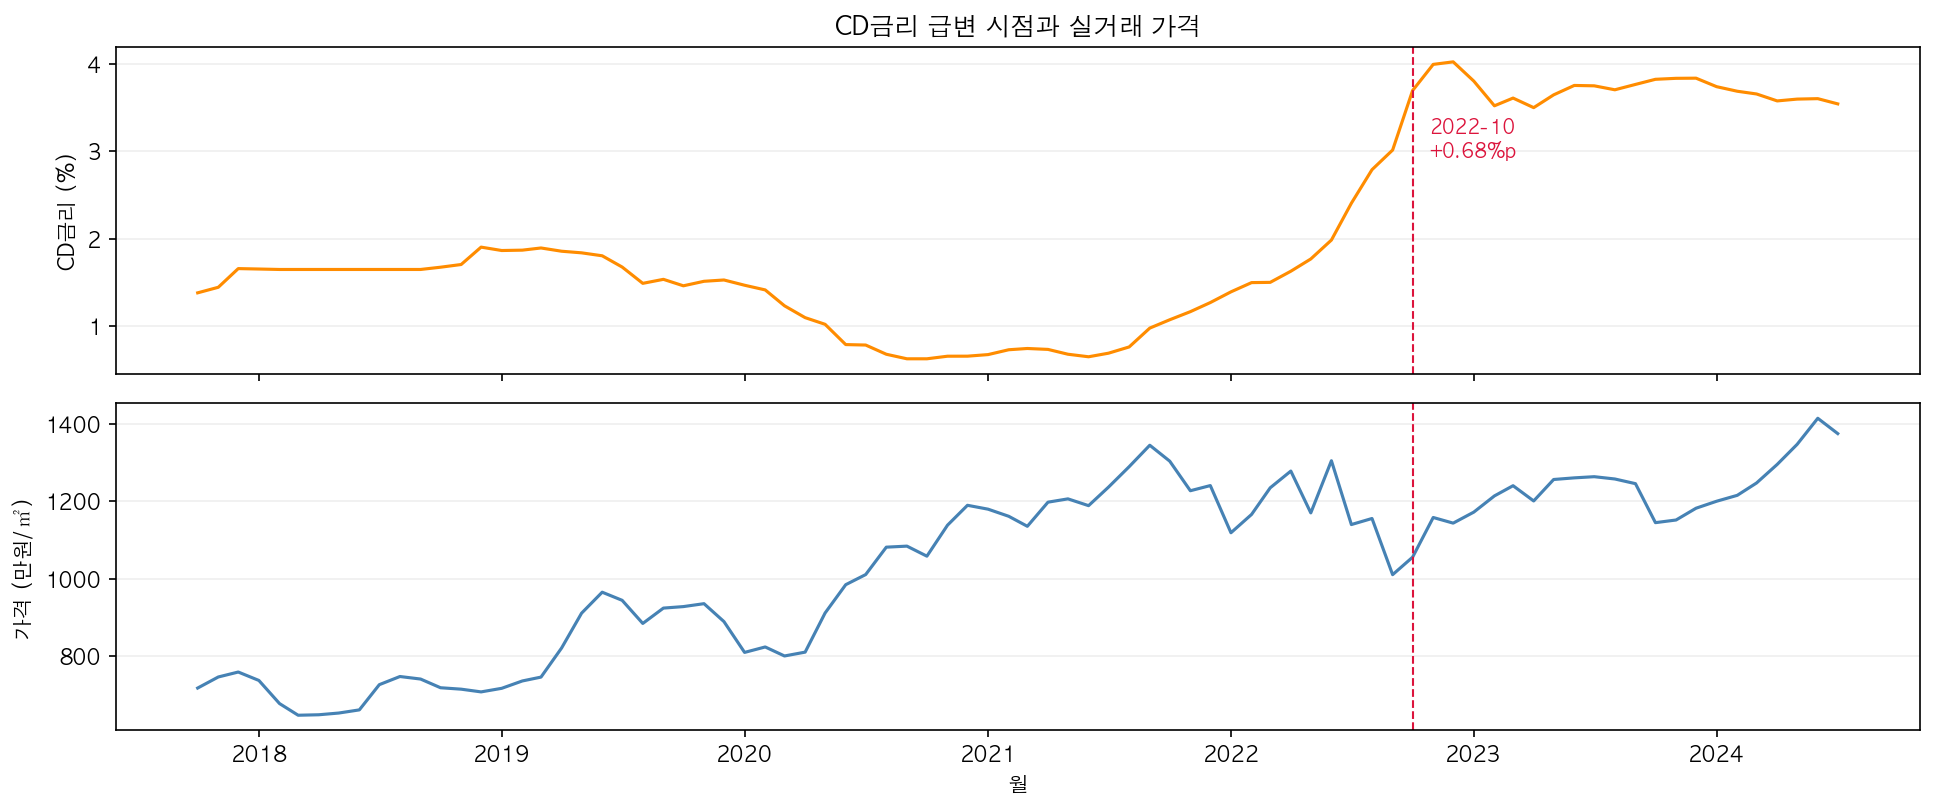

In [7]:
# 금리와 가격을 같은 기간의 두 축에 나누어 표시해 서로 다른 단위를 구분한다.
common = monthly.join(interest, how='inner').dropna(subset=['가격', 'CD금리_pct'])
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
axes[0].plot(common.index, common['CD금리_pct'], color='darkorange')
axes[0].set(title='CD금리 급변 시점과 실거래 가격', ylabel='CD금리 (%)')
axes[1].plot(common.index, common['가격'], color='steelblue')
axes[1].set(ylabel='가격 (만원/㎡)', xlabel='월')
for ax in axes:
    for date in shocks.index:
        ax.axvline(date, color='crimson', linestyle='--', linewidth=1)
    ax.grid(axis='y', alpha=.2)
for date, r in shocks.iterrows():
    axes[0].annotate(f"{date:%Y-%m}\n{r['전월차_pctp']:+.2f}%p",
                     xy=(date, r['CD금리_pct']), xytext=(8, -32),
                     textcoords='offset points', fontsize=9, color='crimson')
fig.tight_layout()
fig.savefig(out/'interest_price_trend.png', dpi=150, bbox_inches='tight')
plt.show()